In [2]:
!pip install Levenshtein

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 177.4/177.4 kB 2.1 MB/s eta 0:00:0000:01


In [5]:
import os
import torch
import evaluate
import numpy as np
import pandas as pd
import glob as glob
import torch.optim as optim
import matplotlib.pyplot as plt
from torch.utils.data import Dataset, DataLoader
from transformers import TrOCRProcessor, VisionEncoderDecoderModel, AutoTokenizer, AutoModelForMaskedLM
from PIL import Image
import torch
import Levenshtein
from dataclasses import dataclass

# Configuration classes
@dataclass(frozen=True)
class TrainingConfig:
    BATCH_SIZE: int = 16
    EPOCHS: int = 10
    LEARNING_RATE: float = 0.00005

@dataclass(frozen=True)
class DatasetConfig:
    DATA_ROOT: str = 'dataset'

@dataclass(frozen=True)
class ModelConfig:
    TROCR_MODEL_NAME: str = 'microsoft/trocr-small-printed'
    BERT_MODEL_PATH: str = 'pretrained_model/bert_module_khmer'

# Custom OCR Dataset
class CustomOCRDataset(Dataset):
    def __init__(self, root_dir, df, processor):
        self.root_dir = root_dir
        self.df = df
        self.processor = processor

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        if torch.is_tensor(idx):
            idx = idx.tolist()

        img_name = os.path.join(self.root_dir, self.df.iloc[idx, 0])
        image = Image.open(img_name).convert("RGB")
        text = str(self.df.iloc[idx, 1])

        pixel_values = self.processor(images=image, return_tensors="pt").pixel_values.squeeze()
        labels = self.processor.tokenizer(text, return_tensors="pt").input_ids.squeeze()

        return {"pixel_values": pixel_values, "labels": labels, "text": text}

# Load the TrOCR model and processor
def load_trocr_model(model_name: str):
    processor = TrOCRProcessor.from_pretrained(model_name)
    model = VisionEncoderDecoderModel.from_pretrained(model_name)
    return processor, model

# Load the Khmer BERT model and tokenizer
def load_bert_model(bert_model_path: str):
    tokenizer = AutoTokenizer.from_pretrained(bert_model_path)
    model = AutoModelForMaskedLM.from_pretrained(bert_model_path)
    return tokenizer, model

# Recognize text from image using TrOCR
def recognize_text_from_image(image_path: str, processor, model):
    image = Image.open(image_path)
    pixel_values = processor(images=image, return_tensors="pt").pixel_values
    outputs = model.generate(pixel_values.to('cuda') if torch.cuda.is_available() else pixel_values)
    predicted_text = processor.batch_decode(outputs, skip_special_tokens=True)[0]
    return predicted_text

# Calculate Character Error Rate (CER)
def calculate_cer(ground_truth, ocr_output):
    return Levenshtein.distance(ground_truth, ocr_output) / max(len(ground_truth), 1)




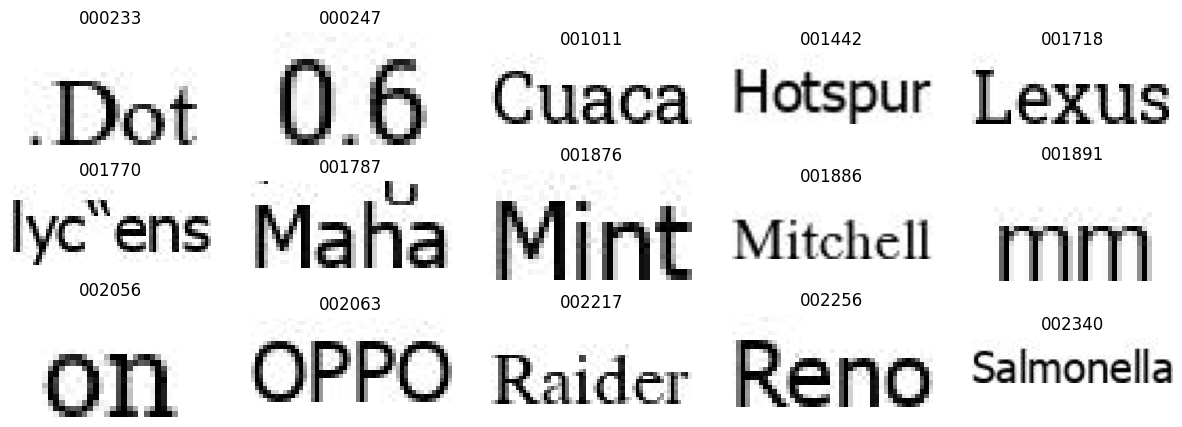

In [6]:
def visualize(dataset_path):
    plt.figure(figsize=(15, 5))
    for i in range(15):
        plt.subplot(3, 5, i+1)
        all_images = os.listdir(f"{dataset_path}/data_train")
        image = plt.imread(f"{dataset_path}/data_train/{all_images[i]}")
        plt.imshow(image)
        plt.axis('off')
        plt.title(all_images[i].split('.')[0])
    plt.show()

visualize(DatasetConfig.DATA_ROOT)

In [7]:
train_df = pd.read_fwf(
    os.path.join(DatasetConfig.DATA_ROOT, 'data_train.txt'), header=None
)
train_df.rename(columns={0: 'file_name', 1: 'text'}, inplace=True)
test_df = pd.read_fwf(
    os.path.join(DatasetConfig.DATA_ROOT, 'data_test.txt'), header=None
)
test_df.rename(columns={0: 'file_name', 1: 'text'}, inplace=True)

In [8]:
train_df.head()

,file_name,text
0,000000.jpg,!(ម៉ានីល
1,000001.jpg,#១
2,000002.jpg,#២
3,000003.jpg,#៥
4,000004.jpg,$109


In [9]:
test_df.head()

,file_name,text
0,022567.jpg,!!!កាលបើ
1,022568.jpg,!Google
2,022569.jpg,$388
3,022570.jpg,$599
4,022571.jpg,(15)


In [10]:
def save_model(model):
    torch.save(model.state_dict(), 'trained_model.pth')

In [11]:
if __name__ == "__main__":
    # # Load train and test DataFrames (ensure these are properly loaded and have 'image_path' and 'text' columns)
    # train_df = pd.read_csv(os.path.join(DatasetConfig.DATA_ROOT, 'train_labels.csv'))
    # test_df = pd.read_csv(os.path.join(DatasetConfig.DATA_ROOT, 'test_labels.csv'))

    # Load the TrOCR processor and model
    processor, model = load_trocr_model(ModelConfig.TROCR_MODEL_NAME)

    # Move model to device
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    model.to(device)

    # Print model and parameter information
    print(model)
    total_params = sum(p.numel() for p in model.parameters())
    print(f"{total_params:,} total parameters.")
    total_trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
    print(f"{total_trainable_params:,} training parameters.")

    # Create training and validation datasets
    train_dataset = CustomOCRDataset(
        root_dir=os.path.join(DatasetConfig.DATA_ROOT, 'data_train/'),
        df=train_df,
        processor=processor
    )

    valid_dataset = CustomOCRDataset(
        root_dir=os.path.join(DatasetConfig.DATA_ROOT, 'data_test/'),
        df=test_df,
        processor=processor
    )

    # Create DataLoaders
    train_loader = DataLoader(train_dataset, batch_size=TrainingConfig.BATCH_SIZE, shuffle=True)
    valid_loader = DataLoader(valid_dataset, batch_size=TrainingConfig.BATCH_SIZE)

    # Set up the training environment
    optimizer = torch.optim.AdamW(model.parameters(), lr=TrainingConfig.LEARNING_RATE)
    model.train()

    # Training loop
    for epoch in range(TrainingConfig.EPOCHS):
        epoch_loss = 0
        for batch in train_loader:
            pixel_values = batch["pixel_values"].to(device)
            labels = batch["labels"].to(device)
            
            outputs = model(pixel_values=pixel_values, labels=labels)
            loss = outputs.loss
            
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            
            epoch_loss += loss.item()
        
        print(f"Epoch {epoch+1}/{TrainingConfig.EPOCHS}, Loss: {epoch_loss/len(train_loader)}")

    print("Training complete.")
    
    # Save the trained model
    save_model(model)

Some weights of VisionEncoderDecoderModel were not initialized from the model checkpoint at microsoft/trocr-small-printed and are newly initialized: ['encoder.pooler.dense.bias', 'encoder.pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


VisionEncoderDecoderModel(
  (encoder): DeiTModel(
    (embeddings): DeiTEmbeddings(
      (patch_embeddings): DeiTPatchEmbeddings(
        (projection): Conv2d(3, 384, kernel_size=(16, 16), stride=(16, 16))
      )
      (dropout): Dropout(p=0.0, inplace=False)
    )
    (encoder): DeiTEncoder(
      (layer): ModuleList(
        (0-11): 12 x DeiTLayer(
          (attention): DeiTAttention(
            (attention): DeiTSelfAttention(
              (query): Linear(in_features=384, out_features=384, bias=True)
              (key): Linear(in_features=384, out_features=384, bias=True)
              (value): Linear(in_features=384, out_features=384, bias=True)
              (dropout): Dropout(p=0.0, inplace=False)
            )
            (output): DeiTSelfOutput(
              (dense): Linear(in_features=384, out_features=384, bias=True)
              (dropout): Dropout(p=0.0, inplace=False)
            )
          )
          (intermediate): DeiTIntermediate(
            (dense): Linear(

RuntimeError: stack expects each tensor to be equal size, but got [8] at entry 0 and [6] at entry 1

In [ ]:

    # Evaluation
cer_total = 0
wer_total = 0
num_samples = len(valid_dataset)
for sample in valid_dataset:
        image_path = os.path.join(DatasetConfig.DATA_ROOT, 'data_test/', sample['image_path'])
        ground_truth_text = sample['text']
        ocr_output_text = recognize_text_from_image(image_path, processor, model)
        cer_total += calculate_cer(ground_truth_text, ocr_output_text)
        cer_avg = cer_total / num_samples
        
        # Optionally, split texts into words for WER calculation
        # ground_truth_words = ground_truth_text.split()
        # ocr_output_words = ocr_output_text.split()
        # wer_total += calculate_wer(ground_truth_words, ocr_output_words)
        # wer_avg = wer_total / num_samples
    
print(f"Average CER: {cer_avg:.4f}")
    # print(f"Average WER: {wer_avg:.4f}")    